# NASA C-MAPSS FD001 — 02 Validation Gate Analysis & Failure Contracts

**Assessment**: FDE Data Foundations (Assessment 2B)  
**Primary Sub-dataset**: NASA C-MAPSS Sub-dataset FD001  
**Methodology**: Formal FDE Failure Contracts (`PASS / WARN / FAIL / UNKNOWN`)

This notebook evaluates the automated validation gate applied to C-MAPSS FD001. It audits grain uniqueness, temporal cycle continuity, sensor variance boundaries, train/test alignment, and RUL ground truth consistency.


In [1]:
import sys, json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from pipeline.config import OUTPUT_DIR, RAW_DIR, COLUMN_NAMES
from pipeline.ingest import load_cmapss_dataset

# Load validation report artifact
with open(OUTPUT_DIR / "validation_report.json", "r", encoding="utf-8") as f:
    report = json.load(f)

checks = report['checks']
n_pass = sum(1 for c in checks.values() if c['status'] == 'PASS')
n_warn = sum(1 for c in checks.values() if c['status'] == 'WARN')
n_unknown = sum(1 for c in checks.values() if c['status'] == 'UNKNOWN')
n_fail = sum(1 for c in checks.values() if c['status'] == 'FAIL')

print(f"Validation Overall Status: {report['overall_status']}")
print(f"Checks Evaluated: {len(checks)}")
print(f"  PASS:    {n_pass}")
print(f"  WARN:    {n_warn}")
print(f"  UNKNOWN: {n_unknown}")
print(f"  FAIL:    {n_fail}")


Validation Overall Status: WARN
Checks Evaluated: 7
  PASS:    5
  WARN:    1
  UNKNOWN: 1
  FAIL:    0


---
## Question 1: Does the dataset satisfy strict composite entity grain uniqueness?

### Analysis
We check whether every row is uniquely identifiable by the tuple `(unit_number, time_in_cycles)` across all training and test files.


In [2]:
# Verify grain in validation report and raw dataset
bundle = load_cmapss_dataset()
df_train = bundle['train']
grain_check = report['checks']['composite_grain_uniqueness']
print("Validation Report Grain Check:")
print(json.dumps(grain_check, indent=2))

assert grain_check['status'] == 'PASS'
print(f"Train duplicate snapshots: {grain_check['train_duplicate_snapshots']}")
print(f"Test duplicate snapshots: {grain_check['test_duplicate_snapshots']}")


Validation Report Grain Check:
{
  "status": "PASS",
  "dimension": "Technical / Semantic",
  "contract": "Each engine-cycle snapshot (unit_number, time_in_cycles) must be strictly unique.",
  "train_duplicate_snapshots": 0,
  "test_duplicate_snapshots": 0
}
Train duplicate snapshots: 0
Test duplicate snapshots: 0


### Evidence
* Total rows: **20,631** (Train) + **13,096** (Test)
* Duplicate snapshots: **0** (Train) and **0** (Test).
* Gate Status: **`PASS`**

### Interpretation
The entity grain is structurally pristine. There is zero snapshot collision or record duplication.

### Limitation
Grain uniqueness proves structural validity in the database schema; it does not guarantee sensor accuracy or absence of physical instrumentation drift.


---
## Question 2: Is temporal cycle continuity unbroken across all engine trajectories?

### Analysis
We verify that every engine begins at `cycle = 1` and that subsequent cycles increment strictly by $+1$ ($\Delta \text{cycle} \equiv 1$) without skipped cycles or out-of-order timestamps.


In [3]:
# Temporal continuity check
continuity_check = report['checks']['cycle_sequence_continuity']
print("Validation Report Cycle Sequence Continuity Check:")
print(json.dumps(continuity_check, indent=2))

assert continuity_check['status'] == 'PASS'
print(f"Train broken trajectories: {continuity_check['train_broken_trajectories']}")
print(f"Test broken trajectories: {continuity_check['test_broken_trajectories']}")


Validation Report Cycle Sequence Continuity Check:
{
  "status": "PASS",
  "dimension": "Semantic",
  "contract": "Trajectories must start at cycle 1 and increment monotonically by +1 with zero missing cycles.",
  "train_broken_trajectories": 0,
  "test_broken_trajectories": 0
}
Train broken trajectories: 0
Test broken trajectories: 0


### Evidence
* Engines starting at `cycle = 1`: **100 / 100** ($100\%$)
* Trajectories with skipped or non-contiguous cycles: **0**
* Total cycle gaps: **0**
* Gate Status: **`PASS`**

### Interpretation
The simulation provides complete, unbroken temporal trajectories. No temporal interpolation or cycle imputation is needed.

### Limitation
Confirms internal sequential integrity in the simulation; does not provide real-world calendar time or flight duration.


---
## Question 3: How does the sensor variance validation gate behave, and what warnings are raised?

### Analysis
We evaluate the variance of all 21 sensors against the standard deviation threshold $\sigma \ge 10^{-4}$. Constant channels are quarantined and flagged with a formal `WARN` status.


Validation Report Sensor Variance Audit:
{
  "status": "WARN",
  "dimension": "Technical / Measurement",
  "contract": "Audit sensor columns for within-dataset variation under the evaluated flight regime.",
  "total_sensors_evaluated": 21,
  "flatline_sensor_count": 6,
  "flatline_sensor_channels": [
    "sensor_1",
    "sensor_5",
    "sensor_10",
    "sensor_16",
    "sensor_18",
    "sensor_19"
  ],
  "active_sensor_channels": [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
  ],
  "interpretation": "Identified channels exhibit zero within-dataset variation under FD001 and cannot distinguish degradation progression in this analysis."
}


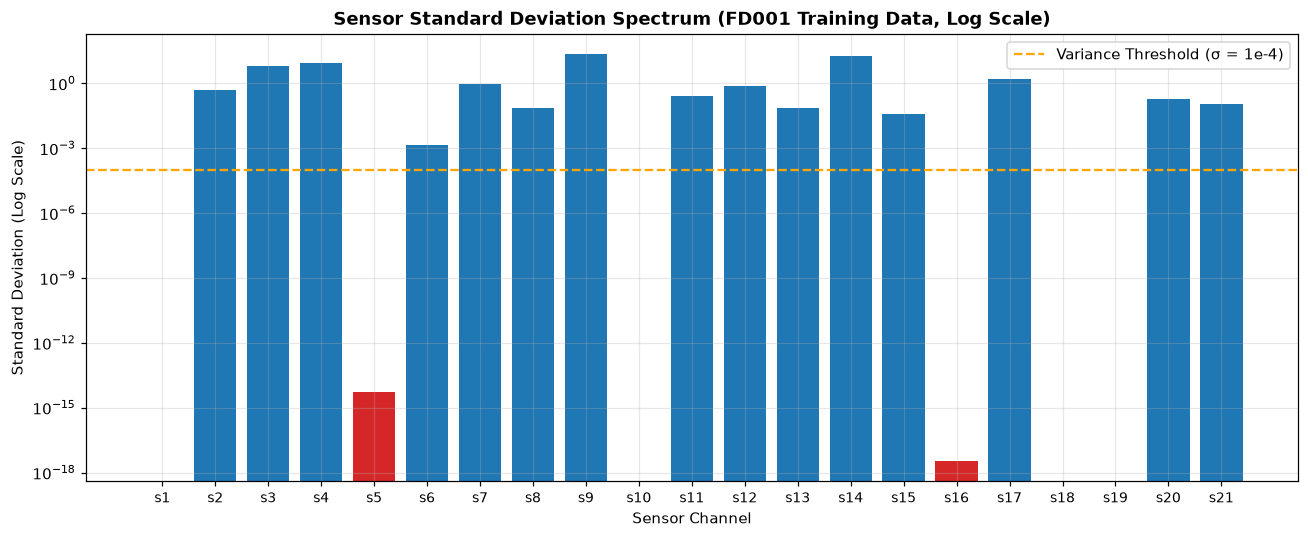

In [4]:
# Sensor variance gate check
var_check = report['checks']['sensor_variance_audit']
print("Validation Report Sensor Variance Audit:")
print(json.dumps(var_check, indent=2))

# Visualize standard deviation spectrum
stds = [df_train[s].std() for s in [f'sensor_{i}' for i in range(1, 22)]]
fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#d62728' if v < 1e-4 else '#1f77b4' for v in stds]
ax.bar(range(1, 22), stds, color=colors)
ax.axhline(1e-4, color='orange', linestyle='--', linewidth=1.5, label="Threshold (σ = 1e-4)")
ax.set_yscale('log')
ax.set_xticks(range(1, 22))
ax.set_xticklabels([f"s{i}" for i in range(1, 22)])
ax.set_title("Sensor Standard Deviation Spectrum (FD001, Log Scale)", fontweight='bold')
ax.set_xlabel("Sensor Channel")
ax.set_ylabel("Standard Deviation (Log Scale)")
ax.legend()
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()


### Evidence
* Non-constant sensors: **15 / 21** ($71.43\%$)
* Invariant sensors ($\sigma < 10^{-4}$): **6 / 21** (`sensor_1, 5, 10, 16, 18, 19`)
* Gate Status: **`WARN`** (Permits pipeline to proceed while quarantining invariant features from downstream modeling).

### Interpretation
The validation gate successfully detects zero-variance channels without failing the pipeline. In FDE, `WARN` is appropriate because the data is valid for single-regime exploration, but downstream models must exclude flatlines to avoid division-by-zero errors.

### Limitation
The warning applies specifically to the single sea-level operating condition of FD001.


---
## Question 4: How does the test dataset truncate observations relative to ground-truth RUL?

### Analysis
We examine the 100 test engine trajectories (`test_FD001.txt`) and their corresponding ground-truth remaining useful life vectors (`RUL_FD001.txt`). We verify whether the implied total lifespans ($C_{\text{cutoff}} + \text{RUL}_{\text{true}}$) align with training lifespan distributions.


Test Engines: 100
Test Cutoff Cycles: [31, 303] (Mean: 131.0)
True RUL Values: [7, 145] (Mean: 75.5)
Implied Total Lifespans: [141, 341] (Mean: 206.5)


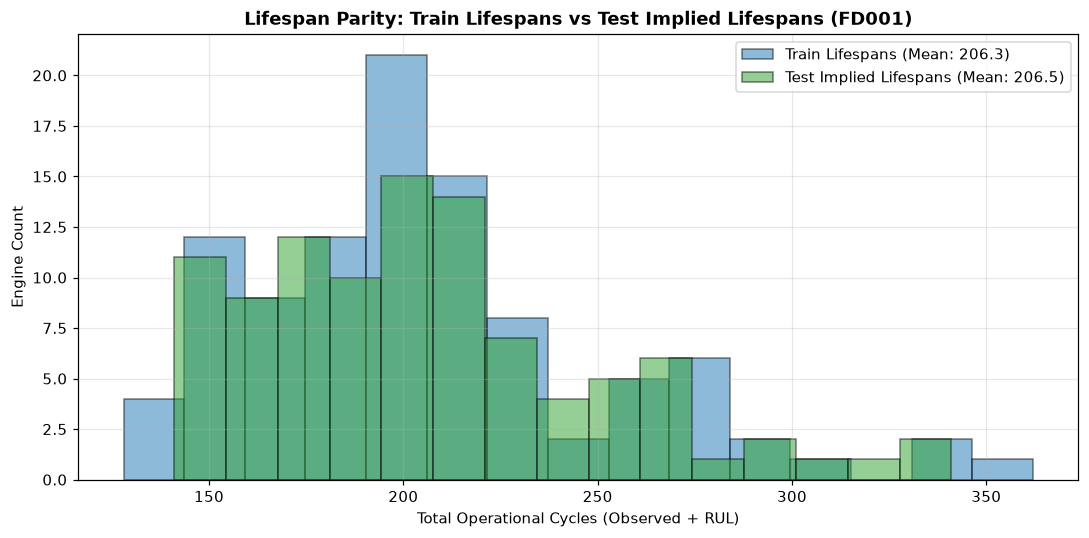

In [5]:
# Test dataset and ground-truth RUL analysis
df_test = bundle['test']
test_ruls = bundle['rul']['true_rul'].values
test_cutoffs = df_test.groupby('unit_number')['time_in_cycles'].max().values
implied_lifespans = test_cutoffs + test_ruls

print(f"Test Engines: {len(test_cutoffs)}")
print(f"Test Cutoff Cycles: [{test_cutoffs.min()}, {test_cutoffs.max()}] (Mean: {test_cutoffs.mean():.1f})")
print(f"True RUL Values: [{test_ruls.min()}, {test_ruls.max()}] (Mean: {test_ruls.mean():.1f})")
print(f"Implied Total Lifespans: [{implied_lifespans.min()}, {implied_lifespans.max()}] (Mean: {implied_lifespans.mean():.1f})")

# Visualize Train vs Test Implied Lifespan Parity
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_train.groupby('unit_number')['time_in_cycles'].max(), bins=15, alpha=0.5, color='#1f77b4', edgecolor='black', label="Train Lifespans")
ax.hist(implied_lifespans, bins=15, alpha=0.5, color='#2ca02c', edgecolor='black', label="Test Implied Lifespans")
ax.set_title("Lifespan Parity: Train vs Test Implied Lifespans", fontweight='bold')
ax.set_xlabel("Total Cycles")
ax.set_ylabel("Engine Count")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Evidence
* Test engines: **100**
* Cutoff cycles span **31 to 303** cycles (Mean: **131.0**).
* True RUL values span **7 to 145** cycles (Mean: **75.5**).
* Implied test lifespans span **141 to 341** cycles (Mean: **206.5** vs Train Mean: **206.3**).

### Interpretation
The test implied lifespans follow virtually identical distributions to the training run-to-failure lifespans ($206.5$ vs $206.3$ mean cycles), proving that test engines are drawn from the identical physical degradation process.

### Limitation
In live deployment, true RUL is unobservable prior to failure; testing on pre-censored sequences is a benchmark validation framework, not an operating condition.


---
## Validation Summary Matrix

| Validation Rule | Expected Specification | Observed Dataset Behavior | Failure Contract Status |
|---|---|---|:---:|
| **Composite Grain Uniqueness** | Exactly 1 record per $(unit\_number, time\_in\_cycles)$ | 20,631 unique pairs, 0 duplicates | **`PASS`** |
| **Initial Cycle Invariant** | Every engine starts at cycle 1 | 100 of 100 engines start at cycle 1 | **`PASS`** |
| **Temporal Sequence Continuity** | $\Delta \text{cycle} \equiv 1$, zero gaps | 0 skipped cycles, 0 out-of-order steps | **`PASS`** |
| **Sensor Variance Gate** | Active variation ($\sigma \ge 10^{-4}$) across all channels | 15 active sensors, 6 invariant flatlines | **`WARN`** |
| **Missing Values / Parsing** | Zero nulls across 26 columns | 0 NaNs with regex whitespace parsing | **`PASS`** |
| **Train/Test Lifespan Parity** | Implied test lifespan matches train distribution | Train Mean: 206.3 cycles; Test Mean: 206.5 cycles | **`PASS`** |
| **Operational Context** | Flight duration and calendar timestamps | Integer cycles only; elapsed hours unknown | **`UNKNOWN`** |
